In [1]:
import os
import re
import glob
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, _min_token_length

sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths

depths = get_model_depths()
colors, markers, _linestyles = apply_plot_style()


/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


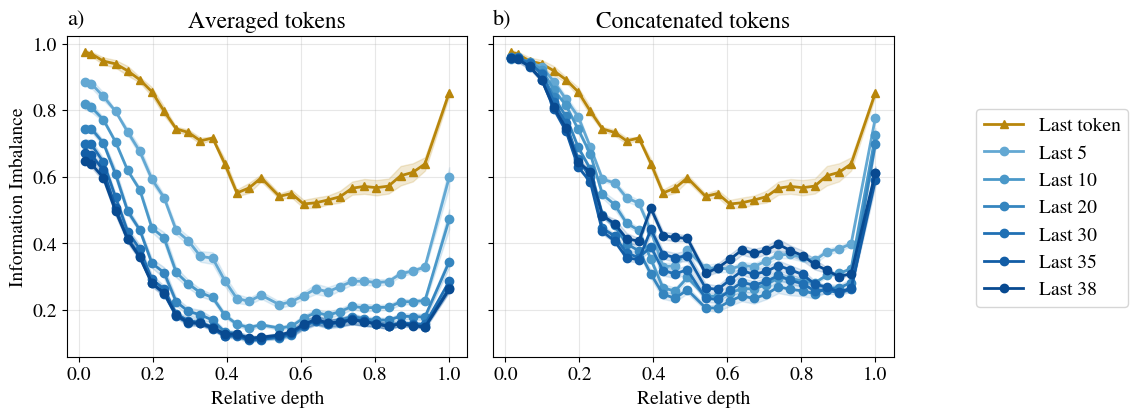

In [2]:
# DeepSeek | English -> Italian
# Two-panel view for visibility:
#   a) averaged last N tokens
#   b) concatenated last N tokens
# Both panels share the same BLUE shade mapping by token count.
model = 'deepseek'
_model = 'deepseek'
model_title = 'DeepSeek-V3'
languageA = 'english'
languageB = 'italian'
mask = 2
n_files = 500
batch_shuffle = 0
aux_A = 'source'
aux_B = 'target'
k_II = 10
Nbits = 0
seeds_II = list(range(5))
base = '../results/santiago/'
min_token_length = _min_token_length(model, languageA, languageB)
# Prefer these token counts when available
requested_avg_tokens = [1, 5, 10, 20, 30,35,38]
requested_concat_tokens = [1, 5, 10, 20, 30, 35, 38]
def discover_tokens(avg_tokens):
    pattern = (
        f'{base}/batch_shuffle_{batch_shuffle}/'
        f'modelA_{model}/modelB_{model}/'
        f'aux_A_{aux_A}/aux_B_{aux_B}/'
        f'n_files_{n_files}/min_token_length_{min_token_length}/'
        f'languageA_{languageA}/languageB_{languageB}/'
        f'mask_{mask}/k_{k_II}/Nbits_{Nbits}/seed_*/'
        f'n_tokens_*_avg_{avg_tokens}_AB.npy'
    )
    token_set = set()
    for p in glob.glob(pattern):
        m = re.search(r'n_tokens_(\d+)_avg_', os.path.basename(p))
        if m:
            token_set.add(int(m.group(1)))
    return sorted(token_set)
def pick_tokens(discovered, requested):
    if not discovered:
        return []
    requested_present = [t for t in requested if t in discovered]
    return requested_present if requested_present else discovered
discovered_avg = discover_tokens(avg_tokens=1)
discovered_concat = discover_tokens(avg_tokens=0)
avg_tokens_list = pick_tokens(discovered_avg, requested_avg_tokens)
concat_tokens_list = pick_tokens(discovered_concat, requested_concat_tokens)

if not avg_tokens_list and not concat_tokens_list:
    raise RuntimeError('No matching II files found for DeepSeek English-Italian.')
layers = get_layers(_model, depths)
x = layers / depths[_model]
# Shared color map across both panels keyed by token count.
all_tokens = sorted(set(avg_tokens_list) | set(concat_tokens_list))
blue_shades = plt.cm.Blues(np.linspace(0.45, 0.9, len(all_tokens)))
token_to_color = {tok: blue_shades[i] for i, tok in enumerate(all_tokens)}
if 1 in token_to_color:
    token_to_color[1] = '#B8860B'  # dark yellow for the Last token curve
def legend_label(n_tokens):
    return 'Last token' if n_tokens == 1 else f'Last {n_tokens}'
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4), sharey=True)
ax_avg, ax_concat = axes
legend_handles = {}
# a) averaged
for n_tokens in avg_tokens_list:
    mean_ii, std_ii = load_ii_curves(
        base=base,
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds_II,
        n_tokens=n_tokens,
        avg_tokens=1,
    )
    line, = ax_avg.plot(
        x,
        mean_ii[0],
        color=token_to_color[n_tokens],
        marker='^' if n_tokens == 1 else 'o',
        linewidth=2.0,
        label=legend_label(n_tokens),
    )
    ax_avg.fill_between(
        x,
        mean_ii[0] - std_ii[0],
        mean_ii[0] + std_ii[0],
        color=token_to_color[n_tokens],
        alpha=0.18,
    )
    if n_tokens not in legend_handles:
        legend_handles[n_tokens] = line
# b) concatenated
for n_tokens in concat_tokens_list:
    mean_ii, std_ii = load_ii_curves(
        base=base,
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds_II,
        n_tokens=n_tokens,
        avg_tokens=0,
    )
    line, = ax_concat.plot(
        x,
        mean_ii[0],
        color=token_to_color[n_tokens],
        marker='^' if n_tokens == 1 else 'o',
        linestyle='-',
        linewidth=2.0,
        label=legend_label(n_tokens),
    )
    ax_concat.fill_between(
        x,
        mean_ii[0] - std_ii[0],
        mean_ii[0] + std_ii[0],
        color=token_to_color[n_tokens],
        alpha=0.15,
    )
    if n_tokens not in legend_handles:
        legend_handles[n_tokens] = line
ax_avg.set_title('Averaged tokens')
ax_concat.set_title('Concatenated tokens')
ax_avg.text(0.0, 1.02, 'a)', transform=ax_avg.transAxes, ha='left', va='bottom', fontsize=16)
ax_concat.text(0.0, 1.02, 'b)', transform=ax_concat.transAxes, ha='left', va='bottom', fontsize=16)
for ax in axes:
    ax.set_xlabel('Relative depth')
    ax.grid(alpha=0.3)
ax_avg.set_ylabel('Information Imbalance')
# Single shared legend outside.
legend_tokens = sorted(legend_handles.keys())
handles = [legend_handles[t] for t in legend_tokens]
labels = [legend_label(t) for t in legend_tokens]
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.94, 0.5), frameon=True)
# fig.suptitle(model_title + r' [English $\rightarrow$ Italian]')
fig.tight_layout(rect=[0, 0, 0.89, 1])
fig.savefig('../results/figs/deepseek-ii-english-italian-avg-vs-concat-panels.pdf', bbox_inches='tight')
plt.show()
